# Classification and Evaluation in NLP

**Text classification** is a common Natural Language Processing (NLP) task where a model assigns a predefined category or label to a piece of text.

Examples include:
- Spam detection
- Sentiment analysis
- News categorization

In this lab, we will learn how to build and evaluate a text classification model.

## Case Study: Sentiment Analysis

Sentiment analysis, also known as opinion mining, its goal is to understand the information present in the text and categorize it as positive, negative, or neutral.

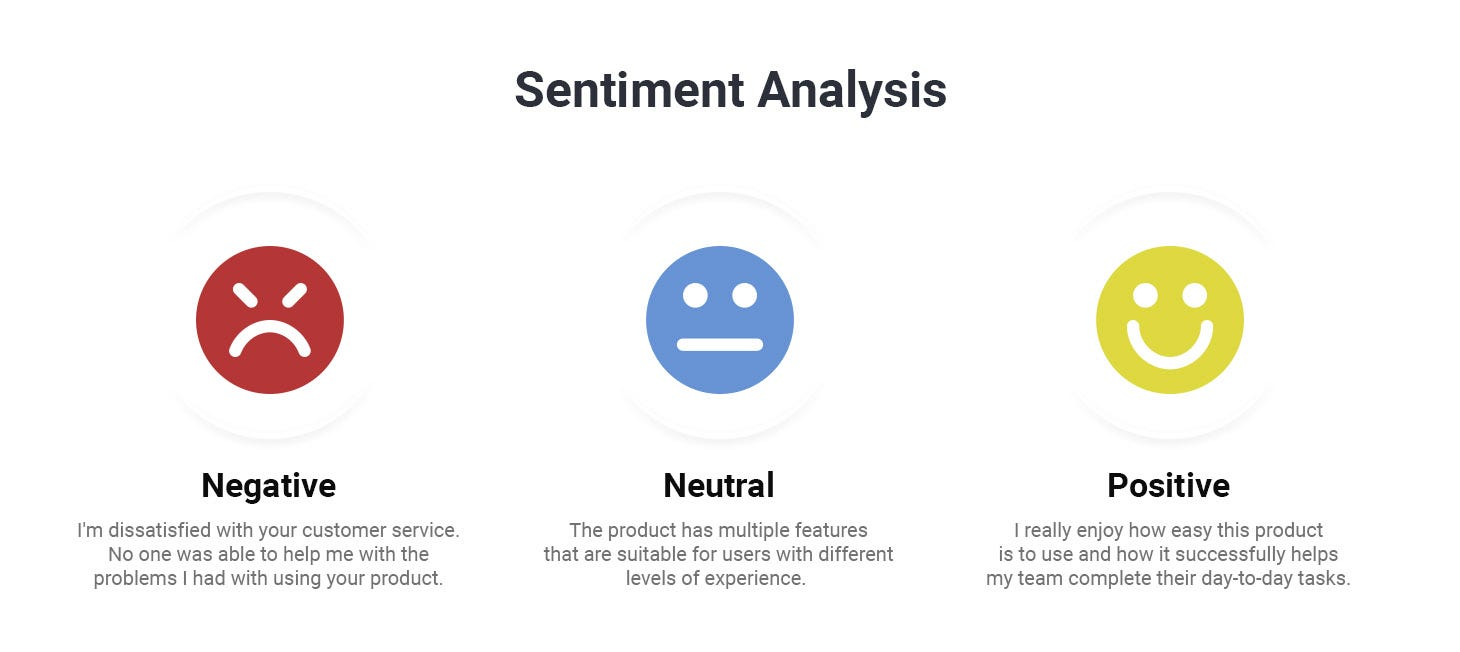

# Disneyland Reviews Dataset
In this lab we'll look into Disneyland Reviews dataset.  
*Link: https://www.kaggle.com/datasets/arushchillar/disneyland-reviews*

The dataset includes 42,000 reviews of 3 Disneyland branches - Paris, California and Hong Kong, posted by visitors on Trip Advisor.

Column Description:

- Review_ID: unique id given to each review
- Rating: ranging from 1 (unsatisfied) to 5 (satisfied)
- Year_Month: when the reviewer visited the theme park
- Reviewer_Location: country of origin of visitor
- Review_Text: comments made by visitor
- Disneyland_Branch: location of Disneyland Park

In [3]:
# Load the dataset
import pandas as pd

data = pd.read_csv('C:\\Users\\abdul\\OneDrive\\Desktop\\nlp_course\\DisneylandReviews.csv', encoding='latin-1')
data

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong
1,670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong
...,...,...,...,...,...,...
42651,1765031,5,missing,United Kingdom,i went to disneyland paris in july 03 and thou...,Disneyland_Paris
42652,1659553,5,missing,Canada,2 adults and 1 child of 11 visited Disneyland ...,Disneyland_Paris
42653,1645894,5,missing,South Africa,My eleven year old daughter and myself went to...,Disneyland_Paris
42654,1618637,4,missing,United States,"This hotel, part of the Disneyland Paris compl...",Disneyland_Paris


In [2]:
#Check for missing values
data.isna().sum()

Review_ID            0
Rating               0
Year_Month           0
Reviewer_Location    0
Review_Text          0
Branch               0
dtype: int64

In [3]:
# Drop rows with missing values in the relevant columns
data = data.dropna(subset=['Review_Text', 'Rating'])

In [7]:
# Map star ratings to sentiments
data['Sentiment'] = data['Rating'].apply(lambda rating: 'positive' if rating > 3 else ('negative' if rating < 3 else 'neutral'))
data.head()

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch,Sentiment
0,670772142,4,2019-4,Australia,if youve ever been to disneyland anywhere youl...,Disneyland_HongKong,positive
1,670682799,4,2019-5,Philippines,its been a while since d last time we visit hk...,Disneyland_HongKong,positive
2,670623270,4,2019-4,United Arab Emirates,thanks god it wasn t too hot or too humid when...,Disneyland_HongKong,positive
3,670607911,4,2019-4,Australia,hk disneyland is a great compact park unfortun...,Disneyland_HongKong,positive
4,670607296,4,2019-4,United Kingdom,the location is not in the city took around ho...,Disneyland_HongKong,positive


In [8]:
# Import necessary libraries
import re
import nltk

def preprocess_text(text):

    # 1. Convert text to lowercase
    text = text.lower()

    # 2. Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # 3. Tokenize the text
    words = text.split()

    return ' '.join(words)

# Apply preprocessing to the review text
data['Review_Text'] = data['Review_Text'].apply(preprocess_text)

# Display cleaned reviews
data[['Review_Text', 'Sentiment']].head()

,Review_Text,Sentiment
0,if youve ever been to disneyland anywhere youl...,positive
1,its been a while since d last time we visit hk...,positive
2,thanks god it wasn t too hot or too humid when...,positive
3,hk disneyland is a great compact park unfortun...,positive
4,the location is not in the city took around ho...,positive


In [6]:
# Import necessary libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Split the dataset into training and testing sets
train_data, test_data, train_labels, test_labels = train_test_split(data['Review_Text'], data['Sentiment'], test_size=0.2, random_state=42)


# TF-IDF Vectorization
tfidf_vectorizer = TfidfVectorizer(max_features=1000)  # You can adjust max_features based on your dataset size - limit vocabulary to the 1000 most informative tokens
train_vectors = tfidf_vectorizer.fit_transform(train_data)
test_vectors = tfidf_vectorizer.transform(test_data)

In [7]:
print(f"train_data size: {train_data.shape}")
print(f"test_data size: {test_data.shape}")

train_data size: (34124,)
test_data size: (8532,)


In [8]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Train the Support Vector Machine (SVM) classifier
svm_classifier = SVC(kernel='linear')
svm_classifier.fit(train_vectors, train_labels)

# Predictions on the test set
predictions = svm_classifier.predict(test_vectors)

# Evaluate the model
accuracy = accuracy_score(test_labels, predictions)
print(f"Accuracy: {accuracy:.2f}")

# Display classification report
print("Classification Report:")
print(classification_report(test_labels, predictions))


Accuracy: 0.84
Classification Report:
              precision    recall  f1-score   support

    negative       0.64      0.54      0.58       720
     neutral       0.48      0.18      0.26      1035
    positive       0.88      0.98      0.92      6777

    accuracy                           0.84      8532
   macro avg       0.66      0.56      0.59      8532
weighted avg       0.81      0.84      0.81      8532



# Use Case:  Amazon reviews of unlocked phone analysis

The objective of this use case is to conduct sentiment analysis on Amazon reviews of unlocked phones, categorizing reviews into three classes: positive, negative, and neutral. The goal is to gain a comprehensive understanding of customer opinions and sentiments regarding various unlocked phone models.

- Dataset link: https://www.kaggle.com/datasets/PromptCloudHQ/amazon-reviews-unlocked-mobile-phones

Task1: Load the data and do 5 different preprocessing steps on it

Task2: Use a proper train and test split

Task3: Do Feature Extraction Using TF-IDF

Task4: Train a Naive Bayes Classifier

Task5: Evaluate the model on the Test Set

Task6: Print the Confusion Matrix

In [4]:
phones = pd.read_csv('C:\\Users\\abdul\\OneDrive\\Desktop\\nlp_course\\Amazon_Unlocked_Mobile.csv')
print(f"Shape: {phones.shape}")
display(phones.head())

# Check for missing values
phones.isna().sum()

Shape: (413840, 6)


,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0
3,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,It works good but it goes slow sometimes but i...,0.0
4,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,Great phone to replace my lost phone. The only...,0.0


Product Name        0
Brand Name      65171
Price            5933
Rating              0
Reviews            70
Review Votes    12296
dtype: int64

In [ ]:

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')

# Drop rows with a missing review text or rating, and remove duplicate reviews
phones = phones.dropna(subset=['Reviews', 'Rating'])
phones = phones.drop_duplicates(subset=['Reviews'])

# Map star ratings to sentiments 
phones['Sentiment'] = phones['Rating'].apply(
    lambda rating: 'positive' if rating > 3 else ('negative' if rating < 3 else 'neutral')
)


stop_words = set(stopwords.words('english')) - {'no', 'nor', 'not'}
lemmatizer = WordNetLemmatizer()

def lemmatize(word):
    return lemmatizer.lemmatize(word)

def preprocess_text(text):
    # 1. Convert text to lowercase
    text = str(text).lower()

    # 2. Remove URLs and HTML tags
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'<.*?>', ' ', text)

    # 3. Expand negative contractions, then remove punctuation, digits and special characters
    text = text.replace("won't", "will not").replace("can't", "can not")
    text = re.sub(r"n't\b", " not", text)
    text = re.sub(r'[^a-z\s]', ' ', text)

    # 4. Tokenize and remove stopwords
    words = [w for w in text.split() if w not in stop_words]

    # 5. Lemmatize each token
    words = [lemmatize(w) for w in words]

    return ' '.join(words)

# Apply preprocessing (original text is kept in 'Reviews')
phones['Clean_Review'] = phones['Reviews'].apply(preprocess_text)

# Remove reviews that are empty after cleaning
phones = phones[phones['Clean_Review'].str.strip() != '']

print(f"Rows after preprocessing: {len(phones)}")
print(phones['Sentiment'].value_counts())
phones[['Reviews', 'Clean_Review', 'Sentiment']].head()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\abdul\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\abdul\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Rows after preprocessing: 162333
Sentiment
positive    103644
negative     44330
neutral      14359
Name: count, dtype: int64


,Reviews,Clean_Review,Sentiment
0,I feel so LUCKY to have found this used (phone...,feel lucky found used phone u not used hard ph...,positive
1,"nice phone, nice up grade from my pantach revu...",nice phone nice grade pantach revue clean set ...,positive
2,Very pleased,pleased,positive
3,It works good but it goes slow sometimes but i...,work good go slow sometimes good phone love,positive
4,Great phone to replace my lost phone. The only...,great phone replace lost phone thing volume bu...,positive


In [10]:
# Task 2: Train / test split
from sklearn.model_selection import train_test_split

# stratify keeps the positive / neutral / negative proportions the same in both sets
# (important because the classes are imbalanced)
train_data, test_data, train_labels, test_labels = train_test_split(
    phones['Clean_Review'],
    phones['Sentiment'],
    test_size=0.2,
    random_state=42,
    stratify=phones['Sentiment']
)

print(f"train_data size: {train_data.shape}")
print(f"test_data size: {test_data.shape}")
print("\nTrain class distribution:")
print(train_labels.value_counts(normalize=True).round(3))
print("\nTest class distribution:")
print(test_labels.value_counts(normalize=True).round(3))

train_data size: (129866,)
test_data size: (32467,)

Train class distribution:
Sentiment
positive    0.638
negative    0.273
neutral     0.088
Name: proportion, dtype: float64

Test class distribution:
Sentiment
positive    0.638
negative    0.273
neutral     0.088
Name: proportion, dtype: float64


In [ ]:
# Task 3: Feature extraction using TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=5)

train_vectors = tfidf_vectorizer.fit_transform(train_data)
test_vectors = tfidf_vectorizer.transform(test_data)

print(f"train_vectors shape: {train_vectors.shape}")
print(f"test_vectors shape: {test_vectors.shape}")
print("Sample features:", tfidf_vectorizer.get_feature_names_out()[:15])

train_vectors shape: (129866, 5000)
test_vectors shape: (32467, 5000)
Sample features: ['ability' 'able' 'able find' 'able get' 'able make' 'able use' 'abroad'
 'absolute' 'absolutely' 'absolutely love' 'absolutely no' 'abuse' 'ac'
 'accept' 'acceptable']


In [ ]:
# Task 4: Train a Naive Bayes classifier
from sklearn.naive_bayes import MultinomialNB

nb_classifier = MultinomialNB(alpha=1.0)   # alpha = Laplace smoothing
nb_classifier.fit(train_vectors, train_labels)

print("Model trained. Classes:", nb_classifier.classes_)

Model trained. Classes: ['negative' 'neutral' 'positive']


In [13]:
# Task 5: Evaluate the model on the test set
from sklearn.metrics import accuracy_score, classification_report

# Predictions on the test set
predictions = nb_classifier.predict(test_vectors)

# Accuracy
accuracy = accuracy_score(test_labels, predictions)
print(f"Accuracy: {accuracy:.2f}")

# Precision, recall and F1 per class
# (zero_division=0 avoids warnings if a class is never predicted)
print("Classification Report:")
print(classification_report(test_labels, predictions, zero_division=0))

Accuracy: 0.83
Classification Report:
              precision    recall  f1-score   support

    negative       0.79      0.79      0.79      8866
     neutral       0.39      0.05      0.09      2872
    positive       0.85      0.95      0.90     20729

    accuracy                           0.83     32467
   macro avg       0.68      0.60      0.59     32467
weighted avg       0.79      0.83      0.80     32467



               pred_negative  pred_neutral  pred_positive
true_negative           7032            95           1739
true_neutral            1041           148           1683
true_positive            853           135          19741


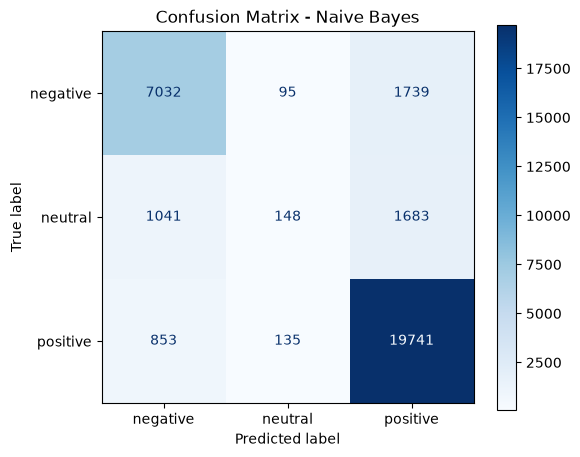

In [14]:
# Task 6: Confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_labels = ['negative', 'neutral', 'positive']
cm = confusion_matrix(test_labels, predictions, labels=class_labels)

# Print as a table (rows = true label, columns = predicted label)
print(pd.DataFrame(
    cm,
    index=[f"true_{c}" for c in class_labels],
    columns=[f"pred_{c}" for c in class_labels]
))

# Plot
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels).plot(
    ax=ax, cmap='Blues', values_format='d'
)
ax.set_title('Confusion Matrix - Naive Bayes')
plt.show()